# 🃏 The Complete Pokémon TCG Dataset: starter analysis

A reproducible first look at **every English Pokémon Trading Card Game card**, from Base Set (1999) to Delta Reign (2026). Fork it, run it top to bottom, and build on it.

**Contents**
1. [Setup and load](#1)
2. [The dataset at a glance](#2)
3. [Cards released per year](#3)
4. [Power creep: HP and damage per Energy](#4)
5. [The rise of rule-box Pokémon](#5)
6. [Card game vs. video game](#6)
7. [The artists](#7)
8. [Takeaways and next steps](#8)

> Data: `cards.csv` (one row per card), `card_attacks.csv` (one row per attack), `sets.csv`, and `card_pokemon.csv`, which links cards to National Pokédex numbers. Section 6 joins [The Complete Pokédex Dataset](https://www.kaggle.com/datasets/cristobalmitchell/pokedex); add it to the notebook's inputs to run that section.

<a id="1"></a>
## 1. Setup and load

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- the house style of the Pokédex starter notebook -------------------------
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, RED = "#2a78d6", "#e34948"
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 120, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.linewidth": 1,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "font.size": 11, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
})

def first_existing(*paths):
    return next((Path(p) for p in paths if Path(p).exists()), None)

# On Kaggle the files sit in /kaggle/input/...; locally, run from the repo's notebooks/ folder.
DATA = first_existing("/kaggle/input/pokemon-tcg", "../data", "data")
POKEDEX = first_existing("/kaggle/input/pokedex/pokemon_utf8.csv", "../../pokedex/data/pokemon_utf8.csv")

# low_memory=False: a few columns mix numbers and text (e.g. level "X" vs "12").
cards = pd.read_csv(DATA / "cards.csv", low_memory=False)
attacks = pd.read_csv(DATA / "card_attacks.csv")
sets = pd.read_csv(DATA / "sets.csv")
links = pd.read_csv(DATA / "card_pokemon.csv")
cards["year"] = cards.release_date.str[:4].astype(int)
print(cards.shape)
cards.head(3)

(20776, 36)


,card_id,set_id,set_name,series,release_date,number,name,supertype,subtypes,level,...,flavor_text,national_numbers,ancient_trait,ancient_trait_text,legal_standard,legal_expanded,legal_unlimited,image_small,image_large,year
0,base1-1,base1,Base,Base,1999-01-09,1,Alakazam,Pokémon,Stage 2,42,...,Its brain can outperform a supercomputer. Its ...,65,NaN,NaN,NaN,NaN,Legal,https://images.pokemontcg.io/base1/1.png,https://images.pokemontcg.io/base1/1_hires.png,1999
1,base1-2,base1,Base,Base,1999-01-09,2,Blastoise,Pokémon,Stage 2,52,...,A brutal Pokémon with pressurized water jets o...,9,NaN,NaN,NaN,NaN,Legal,https://images.pokemontcg.io/base1/2.png,https://images.pokemontcg.io/base1/2_hires.png,1999
2,base1-3,base1,Base,Base,1999-01-09,3,Chansey,Pokémon,Basic,55,...,A rare and elusive Pokémon that is said to bri...,113,NaN,NaN,NaN,NaN,Legal,https://images.pokemontcg.io/base1/3.png,https://images.pokemontcg.io/base1/3_hires.png,1999


<a id="2"></a>
## 2. The dataset at a glance

In [2]:
print(f"Cards:          {len(cards):,}  ({cards.year.min()}–{cards.year.max()})")
print(f"Sets / series:  {len(sets)} sets in {sets.series.nunique()} series")
print(f"Attacks:        {len(attacks):,}")
print(f"Illustrators:   {cards.artist.nunique():,}")
print()
print(cards.supertype.value_counts().to_string())

Cards:          20,776  (1999–2026)
Sets / series:  177 sets in 17 series
Attacks:        28,412
Illustrators:   408

supertype
Pokémon    17543
Trainer     2836
Energy       397


In [3]:
# Missing values mostly mean "not applicable" (Trainer cards have no HP or attacks).
miss = (cards.isna().mean() * 100).round(1)
miss[miss > 0].sort_values(ascending=False).to_frame("percent_missing").head(12)

,percent_missing
ancient_trait_text,99.7
ancient_trait,99.7
level,88.4
resistance_value,76.2
resistance_type,76.2
legal_standard,69.9
rules,69.2
evolves_to,68.7
evolves_from,64.0
regulation_mark,59.1


<a id="3"></a>
## 3. Cards released per year

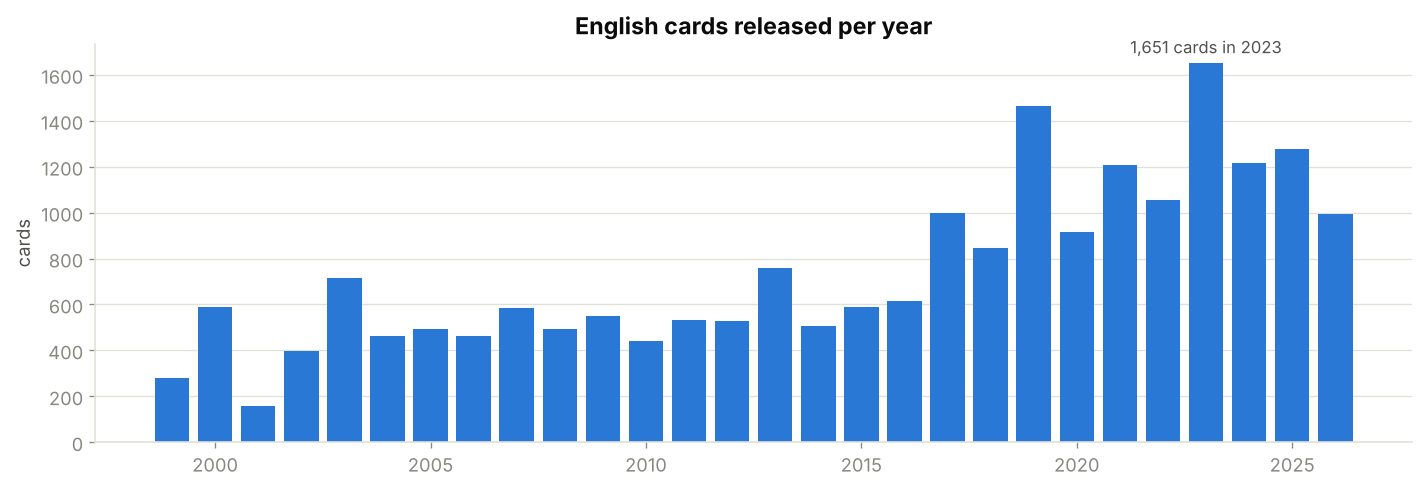

In [4]:
per_year = cards.groupby("year").size()
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(per_year.index, per_year.values, color=BLUE, width=0.8)
peak = per_year.idxmax()
ax.annotate(f"{per_year.max():,} cards in {peak}", (peak, per_year.max()), xytext=(0, 6),
            textcoords="offset points", ha="center", fontsize=10, color=INK2)
ax.set_title("English cards released per year")
ax.set_ylabel("cards")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

<a id="4"></a>
## 4. Power creep: HP and damage per Energy

Two measures on different scales, so two charts rather than one with two y-axes. Both use the yearly **median**, which is robust to the occasional 300-HP outlier.

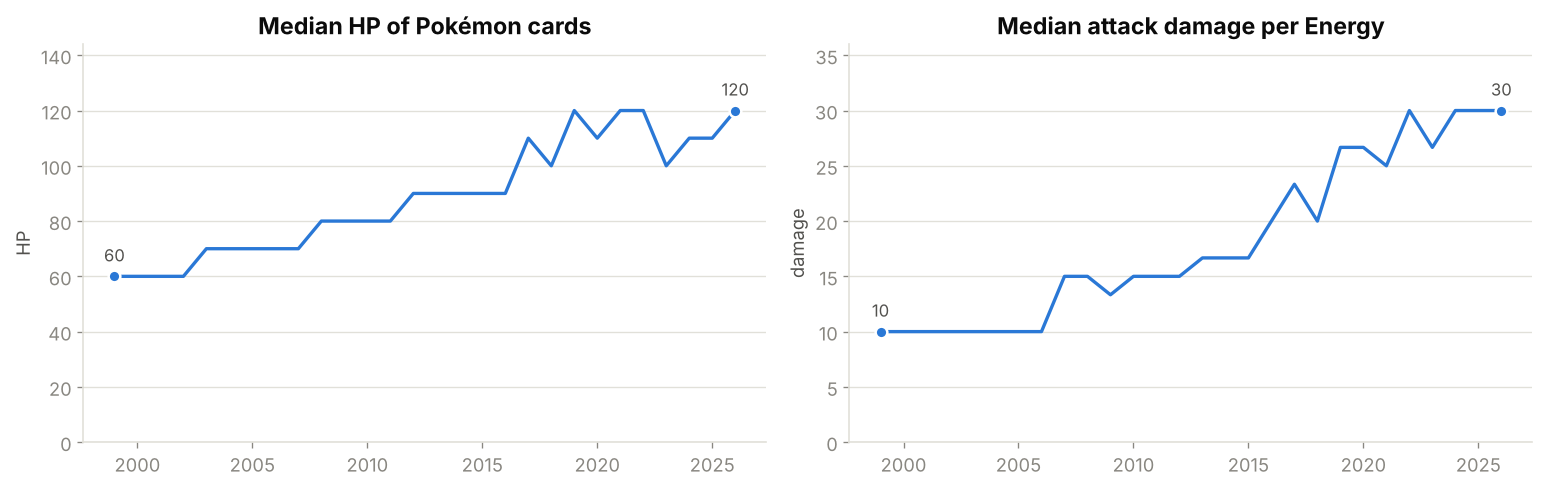

HP: 60 -> 120 (x2.0);  damage per Energy: 10 -> 30 (x3.0)


In [5]:
poke = cards[cards.supertype == "Pokémon"]
hp = poke.groupby("year").hp.median()

a = attacks.merge(cards[["card_id", "year"]], on="card_id")
a = a[(a.converted_energy_cost > 0) & a.base_damage.notna()]
dpe = (a.base_damage / a.converted_energy_cost).groupby(a.year).median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for ax, s, title, unit in [(axes[0], hp, "Median HP of Pokémon cards", "HP"),
                           (axes[1], dpe, "Median attack damage per Energy", "damage")]:
    ax.plot(s.index, s.values, color=BLUE, linewidth=2)
    ax.plot([s.index[0], s.index[-1]], [s.iloc[0], s.iloc[-1]], "o", color=BLUE, ms=7, mec="white", mew=1.5)
    ax.annotate(f"{s.iloc[0]:.0f}", (s.index[0], s.iloc[0]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=10, color=INK2)
    ax.annotate(f"{s.iloc[-1]:.0f}", (s.index[-1], s.iloc[-1]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=10, color=INK2)
    ax.set_title(title); ax.set_ylabel(unit); ax.set_ylim(0, s.max() * 1.2)
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"HP: {hp.iloc[0]:.0f} -> {hp.iloc[-1]:.0f} (x{hp.iloc[-1] / hp.iloc[0]:.1f});  "
      f"damage per Energy: {dpe.iloc[0]:.0f} -> {dpe.iloc[-1]:.0f} (x{dpe.iloc[-1] / dpe.iloc[0]:.1f})")

<a id="5"></a>
## 5. The rise of rule-box Pokémon

ex, EX, GX, V, VMAX, VSTAR, TAG TEAM and Mega cards carry a **rule box** (e.g. "When your Pokémon ex is Knocked Out, your opponent takes 2 Prize cards"). How much of each year's Pokémon cards are these premium cards?

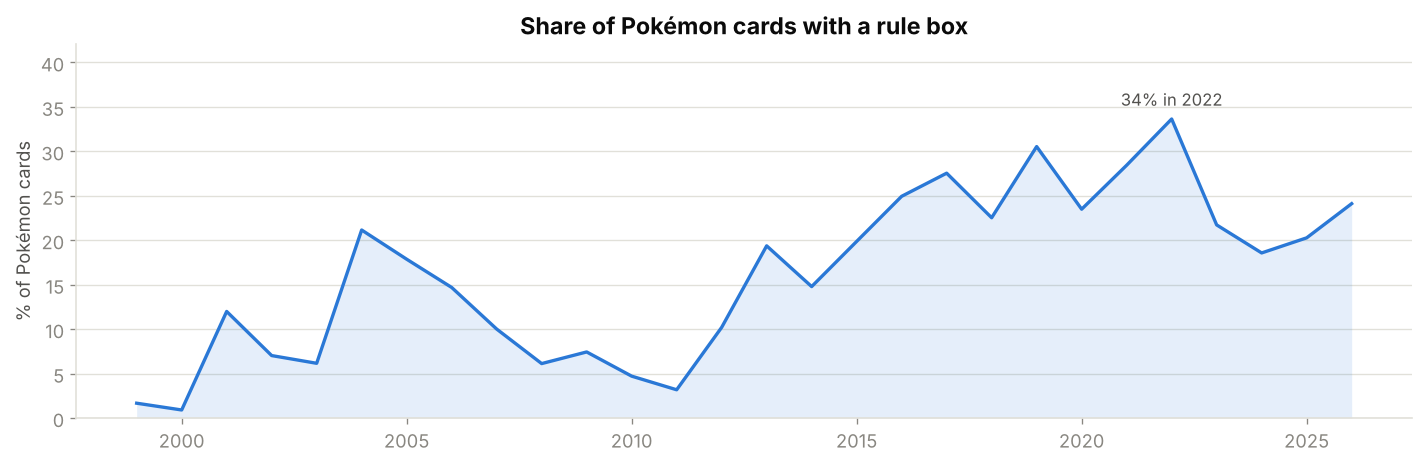

In [6]:
share = poke.assign(rule_box=poke.rules.notna()).groupby("year").rule_box.mean() * 100
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(share.index, share.values, color=BLUE, linewidth=2)
ax.fill_between(share.index, 0, share.values, color=BLUE, alpha=0.12, linewidth=0)
top = share.idxmax()
ax.annotate(f"{share.max():.0f}% in {top}", (top, share.max()), xytext=(0, 8), textcoords="offset points",
            ha="center", fontsize=10, color=INK2)
ax.set_title("Share of Pokémon cards with a rule box")
ax.set_ylabel("% of Pokémon cards"); ax.set_ylim(0, max(share.max() * 1.25, 10))
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

<a id="6"></a>
## 6. Card game vs. video game

Does a Pokémon's HP on cards track its HP stat in the games? Join `card_pokemon.csv` to the Pokédex dataset by National Pokédex number. Only regular cards are used (no rule-box cards, which are built to be bigger), one point per species: its median card HP.

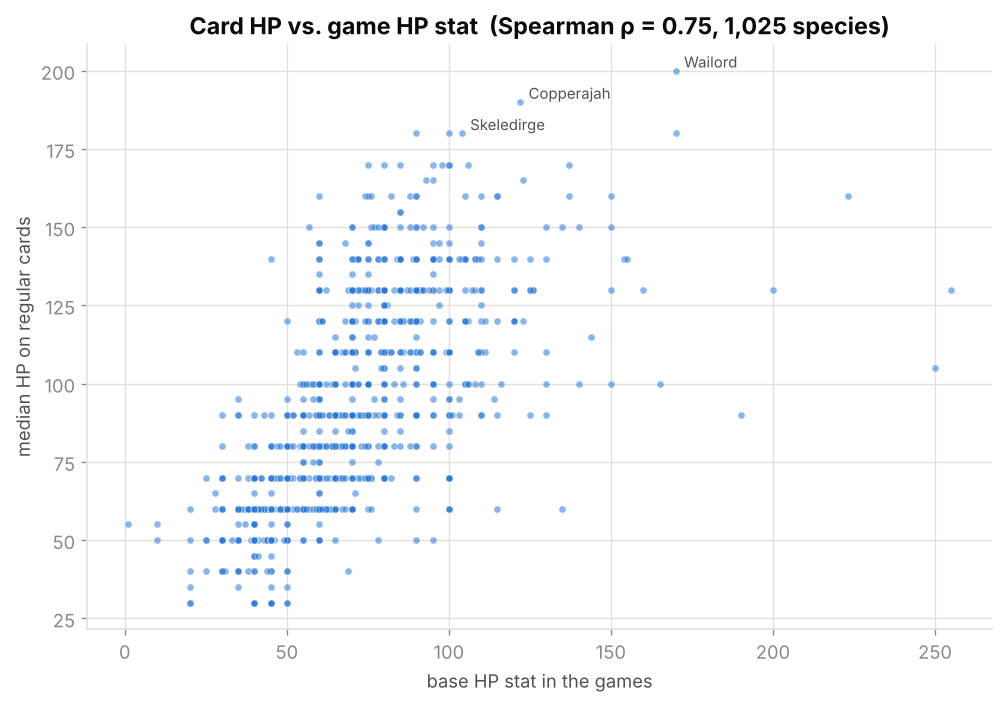

In [7]:
if POKEDEX is None:
    print("Add The Complete Pokédex Dataset (cristobalmitchell/pokedex) to this notebook's inputs to run this section.")
else:
    pokedex = pd.read_csv(POKEDEX)
    single = links.groupby("card_id").filter(lambda g: len(g) == 1)          # one Pokémon per card
    regular = poke[poke.rules.isna() & poke.hp.notna()][["card_id", "hp"]]
    per_species = (single.merge(regular, on="card_id")
                   .groupby("national_number").hp.median().rename("card_hp").reset_index()
                   .merge(pokedex[["national_number", "english_name", "hp", "is_legendary"]], on="national_number"))
    rho = per_species[["card_hp", "hp"]].corr(method="spearman").iloc[0, 1]

    fig, ax = plt.subplots(figsize=(8.5, 6))
    ax.scatter(per_species.hp, per_species.card_hp, s=18, color=BLUE, alpha=0.55, edgecolors="white", linewidths=0.4)
    for _, r in per_species.nlargest(3, "card_hp").iterrows():
        ax.annotate(r.english_name, (r.hp, r.card_hp), xytext=(5, 2), textcoords="offset points",
                    fontsize=9, color=INK2)
    ax.set_title(f"Card HP vs. game HP stat  (Spearman ρ = {rho:.2f}, {len(per_species):,} species)")
    ax.set_xlabel("base HP stat in the games"); ax.set_ylabel("median HP on regular cards")
    plt.tight_layout(); plt.show()

<a id="7"></a>
## 7. The artists

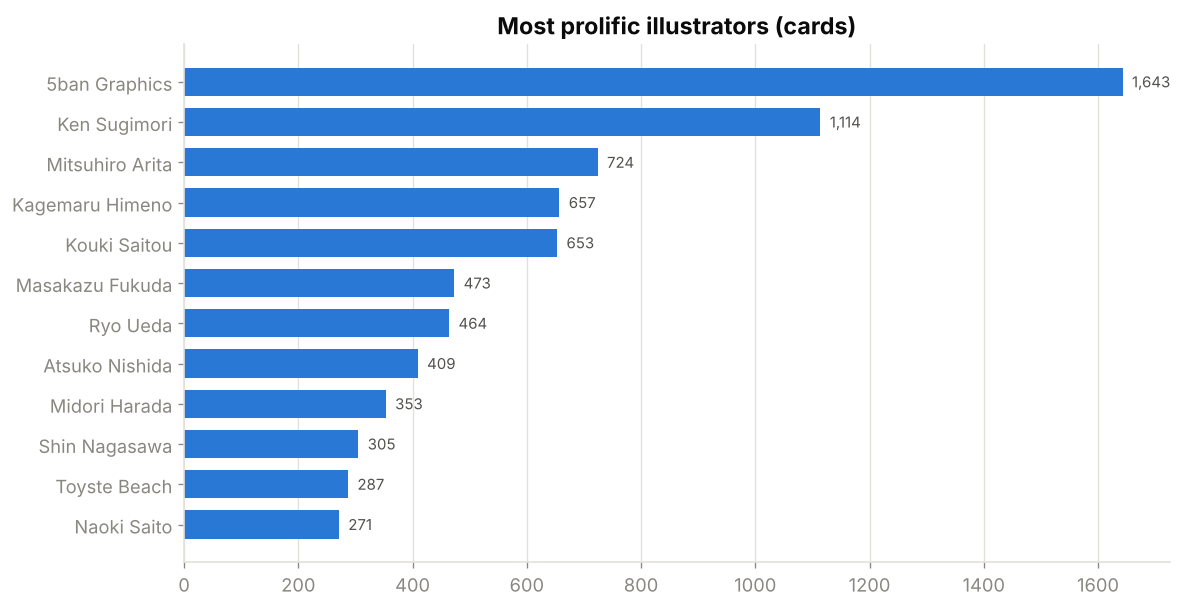

In [8]:
top = cards.artist.value_counts().head(12).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
for i, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, i, f"{v:,}", va="center", fontsize=9, color=INK2)
ax.set_title("Most prolific illustrators (cards)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

<a id="8"></a>
## 8. Takeaways and next steps

- **Power creep is real and measurable:** between 1999 and 2026 the median HP of Pokémon cards doubled (60 → 120) and the median attack damage per Energy tripled (10 → 30).
- **Premium rule-box cards** rose from about 2% of Pokémon cards in 1999 to between 19% and 34% of them every year since 2016 (peak in 2022), after an early ex-era spike in 2004.
- **Card HP follows the games:** across all 1,025 species, median card HP and the HP stat have a Spearman rank correlation of 0.75.

**Ideas to take further**
- Model card HP from game stats, typing and evolution stage (regression).
- Cluster attacks by cost, damage and text into archetypes (NLP + clustering).
- Track how rarity names changed: Rare Holo → Ultra Rare → Illustration Rare → Special Illustration Rare.
- Analyse theme decks (`decks.csv`, `deck_cards.csv`): energy curves and type balance.
- Query everything with SQL in `tcg.sqlite`.

*If this helped, an upvote is appreciated. Tell me in the comments what you'd like analysed next.*